In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv('/Users/raychielle/Desktop/nova_pay/fraudulent_transaction_detector/data/nova_pay_combined.csv')

In [7]:
df.head()

,transaction_id,customer_id,timestamp,home_country,source_currency,dest_currency,channel,amount_src,amount_usd,fee,...,ip_risk_score,kyc_tier,account_age_days,device_trust_score,chargeback_history_count,risk_score_internal,txn_velocity_1h,txn_velocity_24h,corridor_risk,is_fraud
0,fee8542d-8ee6-4b0d-9671-c294dd08ed26,402cccc9-28de-45b3-9af7-cc5302aa1f93,2022-10-03 18:40:59.468549+00:00,US,USD,CAD,ATM,278.19,278.19,4.25,...,0.123,standard,263,0.522,0,0.223,0,0,0.0,0
1,bfdb9fc1-27fe-4a85-b043-4d813d679259,67c2c6b3-ef0a-4777-a3f1-c84a851bb6ad,2022-10-03 20:39:38.468549+00:00,CA,CAD,MXN,web,208.51,154.29,4.24,...,0.569,standard,947,0.475,0,0.268,0,1,0.0,0
2,fc855034-3ea5-4993-9afa-b511d93fe5e8,6d0d9b27-fa26-45f8-93b1-2df29d182d9c,2022-10-03 23:02:43.468549+00:00,US,USD,CNY,mobile,160.33,160.33,2.70,...,0.437,enhanced,367,0.939,0,0.176,0,0,0.0,0
3,2cf8c08e-42ec-444d-a755-34b9a2a0a4ca,7bd5200c-5d19-44f0-9afe-8b339a05366b,2022-10-04 01:08:53.468549+00:00,US,USD,EUR,mobile,59.41,59.41,2.22,...,0.594,standard,147,0.551,0,0.391,0,0,0.0,0
4,d907a74d-b426-438d-97eb-dbe911aca91c,70a93d26-8e3a-4179-900c-a4a7a74d08e5,2022-10-04 09:35:03.468549+00:00,US,USD,INR,mobile,200.96,200.96,3.61,...,0.121,enhanced,257,0.894,0,0.257,0,0,0.0,0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11400 entries, 0 to 11399
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   transaction_id             11400 non-null  object 
 1   customer_id                11400 non-null  object 
 2   timestamp                  11371 non-null  object 
 3   home_country               11400 non-null  object 
 4   source_currency            11400 non-null  object 
 5   dest_currency              11400 non-null  object 
 6   channel                    11400 non-null  object 
 7   amount_src                 11400 non-null  object 
 8   amount_usd                 11095 non-null  float64
 9   fee                        11105 non-null  float64
 10  exchange_rate_src_to_dest  11400 non-null  float64
 11  device_id                  11400 non-null  object 
 12  new_device                 11400 non-null  bool   
 13  ip_address                 11095 non-null  obj

In [9]:
df.isnull().sum()

transaction_id                 0
customer_id                    0
timestamp                     29
home_country                   0
source_currency                0
dest_currency                  0
channel                        0
amount_src                     0
amount_usd                   305
fee                          295
exchange_rate_src_to_dest      0
device_id                      0
new_device                     0
ip_address                   305
ip_country                   301
location_mismatch              0
ip_risk_score                  0
kyc_tier                     300
account_age_days               0
device_trust_score           295
chargeback_history_count       0
risk_score_internal            0
txn_velocity_1h                0
txn_velocity_24h               0
corridor_risk                  0
is_fraud                       0
dtype: int64

In [11]:
missing = df.isnull().sum()
missing_percent = (missing / len(df) * 100).round(2)

In [12]:
missing_df = pd.DataFrame({
    "Missing Count": missing,
    "Missing %": missing_percent
})

print("Columns with missing values:")
print(missing_df[missing_df["Missing Count"] > 0])

Columns with missing values:
                    Missing Count  Missing %
timestamp                      29       0.25
amount_usd                    305       2.68
fee                           295       2.59
ip_address                    305       2.68
ip_country                    301       2.64
kyc_tier                      300       2.63
device_trust_score            295       2.59


In [14]:
## Check for fraud distribution
df["is_fraud"].value_counts()
print("\nFraud percentage:")
print((df["is_fraud"].mean() * 100).round(2), "%")


Fraud percentage:
8.75 %


In [16]:
### Crosscheck categorical columns 
### Country
print(df["home_country"].unique())

['US' 'CA' 'UK' ' UK  ' ' US  ' 'unknown' ' CA  ']


In [17]:
### Channel
print(df["channel"].unique())

['ATM' 'web' 'mobile' 'WEB' ' web  ' 'MOBILE' 'mobille' 'unknown'
 ' mobile  ' 'weeb' 'ATm' ' ATM  ']


In [18]:
### KYC tier
print(df["kyc_tier"].unique())

['standard' 'enhanced' 'low' ' standard  ' nan 'standrd' ' enhanced  '
 'STANDARD' 'NAN' 'unknown' 'enhancd' ' low  ' 'ENHANCED' 'LOW' ' nan  ']


In [19]:
### There are typos in the categorical columns, we need to fix them.

# Strip spaces and convert to uppercase
df["home_country"] = df["home_country"].astype(str).str.strip().str.upper()
df["channel"] = df["channel"].astype(str).str.strip().str.upper()
df["kyc_tier"] = df["kyc_tier"].astype(str).str.strip().str.upper()

In [20]:
# Fix typos
df["channel"] = df["channel"].replace({
    "MOBILLE": "MOBILE",
    "WEEB": "WEB",
    "ATM": "ATM"
})

In [21]:
### Fix typos in kyc_tier
df["kyc_tier"] = df["kyc_tier"].replace({
    "STANDRD": "STANDARD",
    "ENHANCD": "ENHANCED",
    "NAN": "UNKNOWN"
})

In [22]:
print("Cleaned home_country:", df["home_country"].unique())

Cleaned home_country: ['US' 'CA' 'UK' 'UNKNOWN']


In [23]:
print("Cleaned channel:", df["channel"].unique())

Cleaned channel: ['ATM' 'WEB' 'MOBILE' 'UNKNOWN']


In [24]:
print("Cleaned kyc_tier:", df["kyc_tier"].unique())

Cleaned kyc_tier: ['STANDARD' 'ENHANCED' 'LOW' 'UNKNOWN']


In [25]:
# Change to datetime and change bad values to NaT
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce", utc=True)

print("Number of invalid timestamps:", df["timestamp"].isna().sum())

Number of invalid timestamps: 61


In [26]:
print("Earliest date:", df["timestamp"].min())
print("Latest date:", df["timestamp"].max())

Earliest date: 2022-10-03 18:40:59.468549+00:00
Latest date: 2025-12-16 00:13:41.468549+00:00


In [31]:
### Negative values 

print("Negative fees before:", (df["fee"] < 0).sum())
print("Negative trust scores before:", (df["device_trust_score"] < 0).sum())

Negative fees before: 101
Negative trust scores before: 204


In [32]:
df.loc[df["fee"] < 0, "fee"] = np.nan
df.loc[df["device_trust_score"] < 0, "device_trust_score"] = np.nan

print("Negative fees after:", (df["fee"] < 0).sum())
print("Negative trust scores after:", (df["device_trust_score"] < 0).sum())

Negative fees after: 0
Negative trust scores after: 0


In [33]:
# Drop rows with invalid timestamp
df = df.dropna(subset=["timestamp"])

In [34]:
# Fill missing categorical values with "UNKNOWN"
df["kyc_tier"] = df["kyc_tier"].replace("NAN", "UNKNOWN").fillna("UNKNOWN")
df["ip_country"] = df["ip_country"].fillna("UNKNOWN")

In [35]:
# Use teh median to Fill missing numeric values
df["amount_usd"] = df["amount_usd"].fillna(df["amount_usd"].median())
df["fee"] = df["fee"].fillna(df["fee"].median())
df["device_trust_score"] = df["device_trust_score"].fillna(df["device_trust_score"].median())

In [36]:
print("Total missing values left:", df.isnull().sum().sum())

Total missing values left: 305


In [37]:
### CReate new important columns to aid analysis
df["corridor"] = df["source_currency"] + " to " + df["dest_currency"]
df["hour"] = df["timestamp"].dt.hour
df["day_name"] = df["timestamp"].dt.day_name()

print(df[["corridor", "hour", "day_name"]].head())

     corridor  hour day_name
0  USD to CAD    18   Monday
1  CAD to MXN    20   Monday
2  USD to CNY    23   Monday
3  USD to EUR     1  Tuesday
4  USD to INR     9  Tuesday


#### EDA

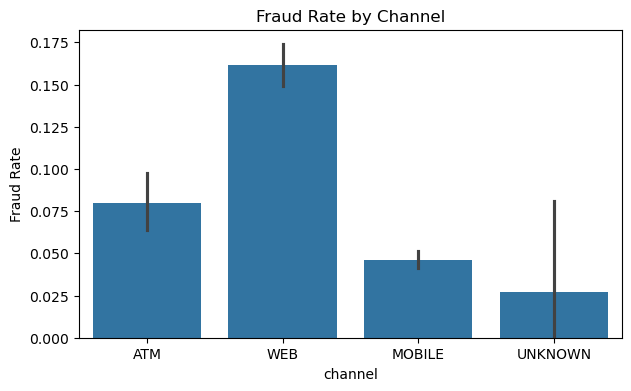

In [38]:
# Fraud rate by channel
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="channel", y="is_fraud", estimator="mean")
plt.title("Fraud Rate by Channel")
plt.ylabel("Fraud Rate")
plt.show()

- Web Has the highest fraudrate
- Followed by ATM
- Mobile 
-Unknown is the lowest.

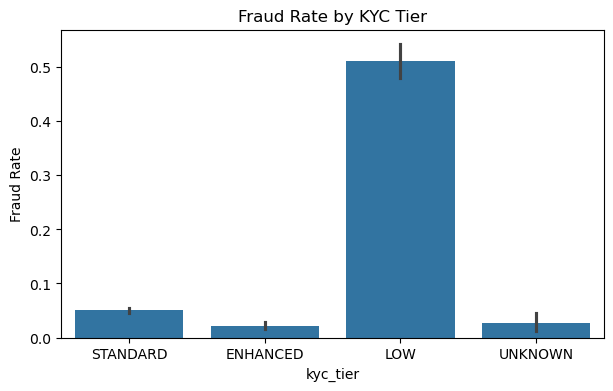

In [39]:
# Fraud rate by KYC tier
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="kyc_tier", y="is_fraud", estimator="mean")
plt.title("Fraud Rate by KYC Tier")
plt.ylabel("Fraud Rate")
plt.show()

##### Accounts with the lowest kyc_tier have the highest fraud rates.

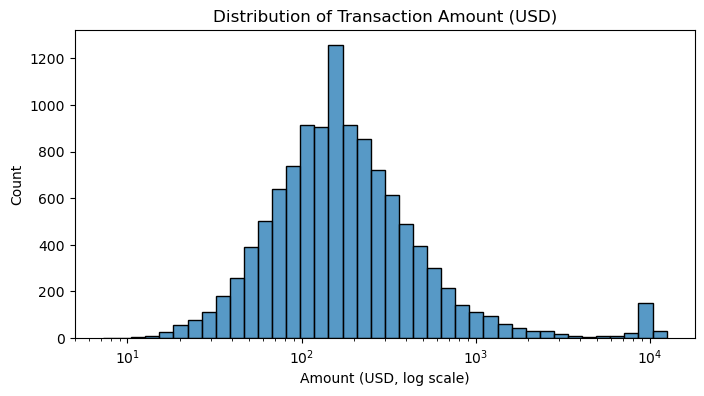

In [40]:
###Transaction Amount Distribution
plt.figure(figsize=(8, 4))
sns.histplot(df["amount_usd"], bins=40, log_scale=True)
plt.title("Distribution of Transaction Amount (USD)")
plt.xlabel("Amount (USD, log scale)")
plt.show()

In [42]:
num_cols = [
    "amount_usd", "fee", "ip_risk_score", "account_age_days",
    "device_trust_score", "risk_score_internal",
    "txn_velocity_1h", "txn_velocity_24h", "corridor_risk"
]

corr = df[num_cols + ["is_fraud"]].corr()["is_fraud"].sort_values(ascending=False)
print("Correlation with is_fraud:")
print(corr)

Correlation with is_fraud:
is_fraud               1.000000
txn_velocity_24h       0.751737
txn_velocity_1h        0.688367
risk_score_internal    0.602002
ip_risk_score          0.520355
corridor_risk          0.193732
amount_usd             0.130196
fee                   -0.013742
account_age_days      -0.284659
device_trust_score    -0.436951
Name: is_fraud, dtype: float64


In [43]:
## Save the cleaned datset
df.to_csv("nova_pay_cleaned.csv", index=False)

In [47]:
df.head()

,transaction_id,customer_id,timestamp,home_country,source_currency,dest_currency,channel,amount_src,amount_usd,fee,...,device_trust_score,chargeback_history_count,risk_score_internal,txn_velocity_1h,txn_velocity_24h,corridor_risk,is_fraud,corridor,hour,day_name
0,fee8542d-8ee6-4b0d-9671-c294dd08ed26,402cccc9-28de-45b3-9af7-cc5302aa1f93,2022-10-03 18:40:59.468549+00:00,US,USD,CAD,ATM,278.19,278.19,4.25,...,0.522,0,0.223,0,0,0.0,0,USD to CAD,18,Monday
1,bfdb9fc1-27fe-4a85-b043-4d813d679259,67c2c6b3-ef0a-4777-a3f1-c84a851bb6ad,2022-10-03 20:39:38.468549+00:00,CA,CAD,MXN,WEB,208.51,154.29,4.24,...,0.475,0,0.268,0,1,0.0,0,CAD to MXN,20,Monday
2,fc855034-3ea5-4993-9afa-b511d93fe5e8,6d0d9b27-fa26-45f8-93b1-2df29d182d9c,2022-10-03 23:02:43.468549+00:00,US,USD,CNY,MOBILE,160.33,160.33,2.70,...,0.939,0,0.176,0,0,0.0,0,USD to CNY,23,Monday
3,2cf8c08e-42ec-444d-a755-34b9a2a0a4ca,7bd5200c-5d19-44f0-9afe-8b339a05366b,2022-10-04 01:08:53.468549+00:00,US,USD,EUR,MOBILE,59.41,59.41,2.22,...,0.551,0,0.391,0,0,0.0,0,USD to EUR,1,Tuesday
4,d907a74d-b426-438d-97eb-dbe911aca91c,70a93d26-8e3a-4179-900c-a4a7a74d08e5,2022-10-04 09:35:03.468549+00:00,US,USD,INR,MOBILE,200.96,200.96,3.61,...,0.894,0,0.257,0,0,0.0,0,USD to INR,9,Tuesday


In [48]:
df.shape

(11339, 29)